# Exercise 1.7

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

In [5]:
# Importing relefvant packages
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib as mpl

This exercise will focus on the dataset for flow past a cylinder. The data is downloaded from the books webpage.

In [6]:
# Loading data set for fluid flow past a cylinder

# DATA SET FOR FLUID FLOW PAST A CYLINDER AT RE=100
# Steven L. Brunton
# May 12, 2016
data = sio.loadmat("CODE/CYLINDER_ALL.mat")

# Check what's inside
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'UALL', 'UEXTRA', 'VALL', 'VEXTRA', 'VORTALL', 'VORTEXTRA', 'm', 'n', 'nx', 'ny'])


In [7]:
# Exporting the relevant data
UALL = data["UALL"] # Velocity U, flattend (nx*ny, t)
VALL = data["VALL"] # Velocity V, flattend (nx*ny, t)
VORTALL = data["VORTALL"] # Vortex flow, flattend (nx*ny, t)
nx = int(data["nx"].item()) # Number of pixels in x direction
ny = int(data["ny"].item()) # Number of pixels in y direction
t = np.shape(VORTALL)[1] # Number of timesteps
print(np.shape(VORTALL))

(89351, 151)


## a)

This exercise will use the vorticity data, VORTALL. The economic SVD is calculated on the entire flattened dataset using mp.lingal.svd, whre full_matrices = False. This is done because only the first 151 rows in ∑, Shat, will contain nonezero values on the diagonal and thereby contains all information (as X = VORTALL is a matrix of 89351 x 151). 
Therefore the economy SVD is much more effective as Uhat will be a matrix of 89351 x 151 instead of 89351 x 89351 and still represent the true Vorticity field.

In [15]:
# Generate Economy SVD from data points
Uhat, Shat, VThat = np.linalg.svd(VORTALL, full_matrices=False)

The ∑ now contain all the singular values from highest to lowest in the diagonal. The singular values are plotted on a log scale, to see its value spectrum.

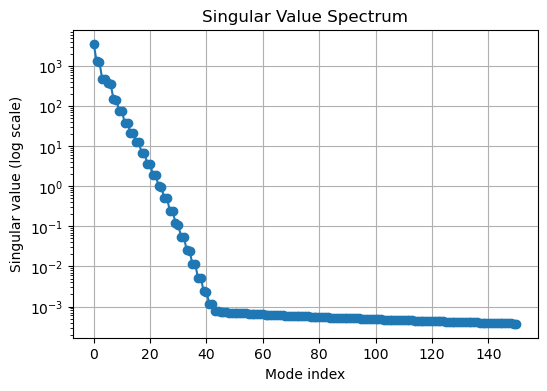

In [16]:
# Plot of the Singular Value Spectrum
plt.figure(figsize=(6, 4))
plt.semilogy(Shat, "o-")
plt.xlabel("Mode index")
plt.ylabel("Singular value (log scale)")
plt.title("Singular Value Spectrum")
plt.grid(True)
plt.show()

Here it can be seen that the most dominent mode has the lowest index and so on through the singular value matrix. As this is on a log scale it is also clear to see that there is quite a large difference in size of magnitude of the singular values, which indicates that perhaps only a few modes are needed to represent most of the flow field.

The two leading singular vectors, the first and second column if U, and their respective amplitudes, the first and second row of ∑V^T, are plotted, to get an idea of the structure of the flow pattern.

In [18]:
# Extracting the leading singular vectors

# Leading LEFT singular vectors
u1 = Uhat[:, 0]
u2 = Uhat[:, 1]

# Leading singular values
s1 = Shat[0]
s2 = Shat[1]

# Leading RIGHT singular vectors
v1 = VThat[0, :]
v2 = VThat[1, :]


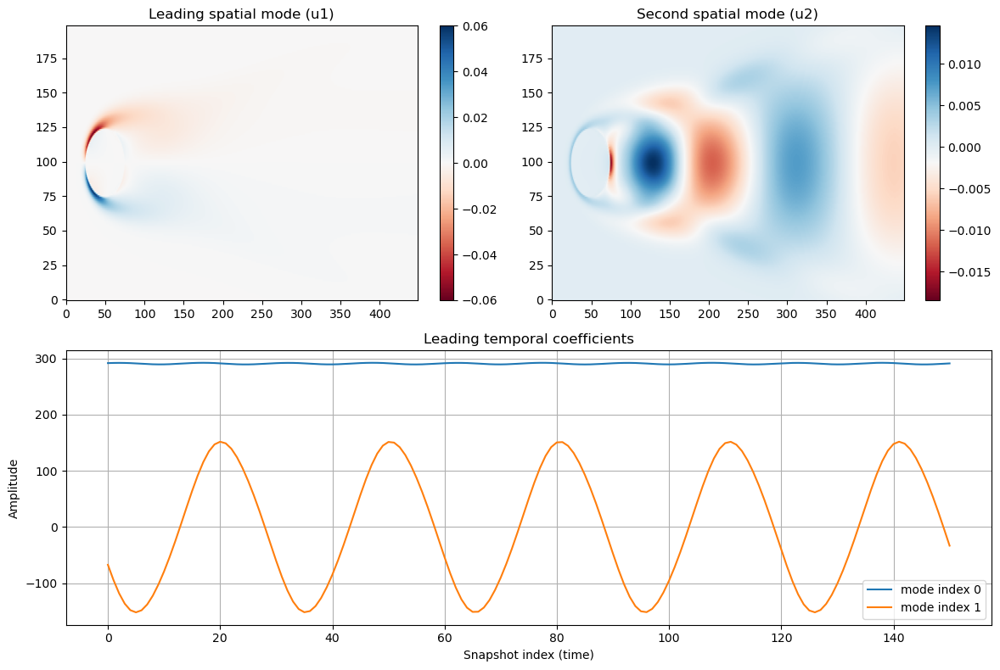

In [ ]:
# Plotting the first 2 modes of the left singular vectors and their amplitudes
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, 2)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, :])  # spans both columns
mode0 = u1.reshape(ny, nx)
mode1 = u2.reshape(ny, nx)
im0 = ax0.imshow(mode0.T, cmap="RdBu", origin="lower", aspect="auto")
ax0.set_title("Leading spatial mode (u1)")
plt.colorbar(im0, ax=ax0)
im1 = ax1.imshow(mode1.T, cmap="RdBu", origin="lower", aspect="auto")
ax1.set_title("Second spatial mode (u2)")
plt.colorbar(im1, ax=ax1)
ax2.plot(s1*v1, label="mode index 0")
ax2.plot(s2*v2, label="mode index 1")
ax2.set_xlabel("Snapshot index (time)")
ax2.set_ylabel("Amplitude")
ax2.set_title("Leading temporal coefficients")
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()


The left singular vectors represent the spatial position of the vortecies. Here it is seen that the leading eigenflow is centered around the inlet of the fluid. This is expected, as this flow profile is present in all snapshots. This can also be seen from the amplitude plot, where the amplitude of this eigenflow is nearly constant around a high value, meaning it has a high presence in all 150 snapshots.

The second leading eigenflow is seen in the upper right plot. This shows the vortics profile behind the cylinder. It shows the periodic nature of the vorticies, which can also be seen by its amplitude profile. This is a periodic function, correcting its relevance for each snapshot through time, clearly outlining the cyclic behavior. The amplitude also accounts for the periodic change in direction, which is seen as the period is centered around 0.

## b)

The singular values are analyzed to indentify the amount of snapshots needed to account for 90, 99 and 99.9% of the flow energy.

This is done by calculating the Frobenius norm cumulatively through the vector of singular values.

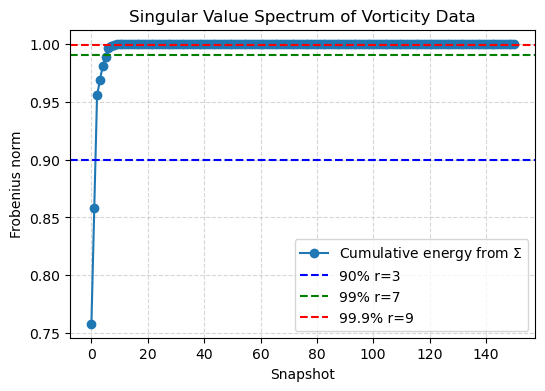

In [22]:
# Find cumulative energy for plot using Frobenius norm
energy_cum = np.cumsum(Shat**2) / np.sum(Shat**2)

#Find ranks for 90, 99 and 99.9 % of captured flow:
r90 = np.argmax(energy_cum >= 0.90) + 1
r99 = np.argmax(energy_cum >= 0.99) + 1
r999 = np.argmax(energy_cum >= 0.999) + 1

#Print singular value spectrum
plt.figure(figsize=(6, 4))
plt.plot(energy_cum, 'o-', label = r"Cumulative energy from $\Sigma$")
plt.axhline(0.9, color = 'b', linestyle = '--', label=f"90% r={r90}")
plt.axhline(0.99, color = 'g', linestyle = '--', label=f"99% r={r99}")
plt.axhline(0.999, color = 'r', linestyle = '--', label=f"99.9% r={r999}")
plt.xlabel("Snapshot")
plt.ylabel("Frobenius norm")
plt.legend()
plt.title("Singular Value Spectrum of Vorticity Data")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

It is here seen that to capture 90%, 99% and 99.9% only the first 3, 7 and 9 modes are needed respectively.

The relative errors related to reconstruction are found for these three ranks.

In [38]:
r = [r90, r99, r999]
errorlist = []
xtildelist = []

for i in r:
    xtilde = Uhat[:, :i] @ np.diag(Shat[:i]) @ VThat[:i, :]
    xtildelist.append(xtilde)

    error = np.linalg.norm(VORTALL - xtilde) ** 2
    relativeerror = error / np.linalg.norm(VORTALL) ** 2

    errorlist.append(relativeerror)

print(f"The relative error between the true matrix and the reconstructed matrix")
for rank, relativeerror in zip(r, errorlist):
    print(f"for rank {rank} is {relativeerror:.3g}, and therefore caputures {(1-relativeerror)*100:.3g}%")

The relative error between the true matrix and the reconstructed matrix
for rank 3 is 0.0447, and therefore caputures 95.5%
for rank 7 is 0.00346, and therefore caputures 99.7%
for rank 9 is 0.000952, and therefore caputures 99.9%


These errors match the values gotten from the Frobenius norm analysis.

A movie showing the snapshots of the 3rd, 7th and 9th rank is now developed.

In [39]:
n_snapshots = xtildelist[0].shape[1]

fig, axes = plt.subplots(
    1, len(r),
    figsize=(5 * len(r), 4),
    squeeze=False
)
axes = axes[0]

ims = []

for ax, xtilde, rank in zip(axes, xtildelist, r):
    frame0 = xtilde[:, 0].reshape(ny, nx)

    im = ax.imshow(
        frame0.T,
        cmap="RdBu",
        origin="lower",
        vmin=-5,
        vmax=5,
        aspect="auto",
    )

    ax.set_title(f"r = {rank}")
    ims.append(im)

fig.suptitle("Snapshot 0")


def update(frame_idx):
    for im, xtilde in zip(ims, xtildelist):
        frame = xtilde[:, frame_idx].reshape(ny, nx)
        im.set_array(frame.T)

    fig.suptitle(f"Snapshot {frame_idx}")
    return ims


ani = animation.FuncAnimation(
    fig,
    update,
    frames=n_snapshots,
    interval=50,
    blit=False,
)

plt.tight_layout()

mpl.rcParams["animation.embed_limit"] = 200   # in MB

display(HTML(ani.to_jshtml()))
plt.close(fig)

From the movies shown above, it can be seen that all three ranks captures the overall vortex flow field very well. However the rank 3 movie shows that some resolution is lost, as it is a bit more blurry than the other two, even thought it captures 95,5 % of the flow field. It is impossible to notice the difference between the rank 7 and rank 9 movies with the naked eye on our computer screens.

All movies clearly show trends from both the first and second leading eigenvalue flow.

## c)

Now the rank is fixed at r = 10, and the truncated SVD is found.

The reconstructed flow patterns from the truncated SVD are compared to the actual vorticies, to evaluate if the flow pattern is recreated sufficiently. This is highly expected from the singular value analysis.

In [49]:
# Computing the truncated SVD for r = 10
r = 10

W = np.diag(Shat[:r]) @ VThat[:r, :]
Uhattrunc = Uhat[:, :r]

# Finding where the error is largest between the true snapshot and the reconstructed vortex field using the truncated SVD
errors = np.array([
    np.linalg.norm(VORTALL[:, i] - Uhattrunc @ W[:, i]) ** 2
    / np.linalg.norm(VORTALL[:, i]) ** 2
    for i in range(t)
])

largest_index = np.argmax(errors)

print(f"Largest relative error: {errors[largest_index]:.3g}")
print(f"This occurs at snapshot: {largest_index + 1}")

Largest relative error: 0.00102
This occurs at snapshot: 117


It is seen that the largest error between the true snapshot and the reconstructed snapshot is only: 0.1%. This shows that the r = 10 truncated SVD represents the flow field sufficiently.

## d)

A linear system, which describes the amplitudes, w_k, in regards to time, snapshot, is now developed. This is done by creating two new truncated matricies, W1 and What, which contain the same values, but are shifted one index:

What = A @ W1

After these two have been created, a new SVD is fitted to W1. From this SVD, A can be calculated by following the example code from multilinear regression of cement data, Code 1.3.

After A has been found, the eigenvalues and eigenvectors of A are found.

In [50]:
# Creating two matrices with the 1 through m-1 columns and 2 through m columns respectively
W1 = W[:, :-1]
What = W[:, 1:]

# Generate economy SVD from W1 (1 through m-1 columns)
UhatW, ShatW, VThatW = np.linalg.svd(W1, full_matrices=False)

UhatW_conj = UhatW.conj().T
VhatW = VThatW.conj().T

# Computing the pseudo inverse of W1 using the SVD
pinvW = VhatW @ np.diag(1 / ShatW) @ UhatW_conj
# Slope from SVD
A = What @ pinvW

# Computing the Eigenvalues and Eigenvectors
Eigenvalues, Eigenvectors = np.linalg.eig(A)

The eigenvalues of A are plotted in the complex plane:

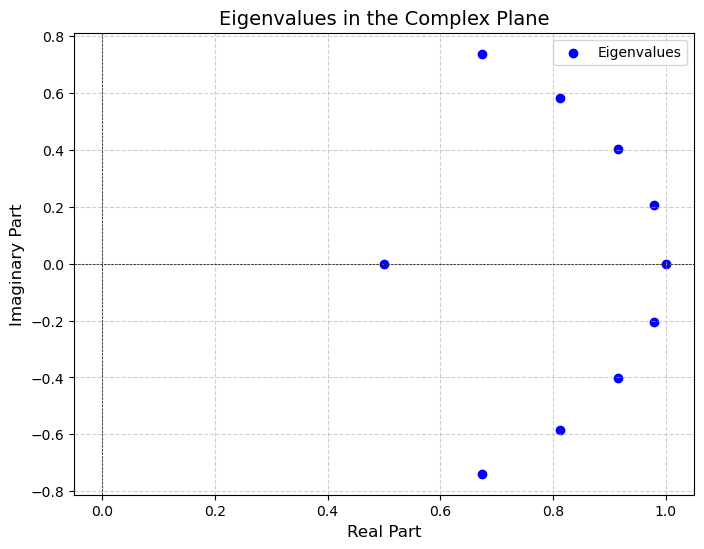

In [51]:
# Plotting the eigenvalues in the complex plane
fig, ax = plt.subplots(figsize=(8, 6))

# Scatter plot of eigenvalues in the complex plane
ax.scatter(Eigenvalues.real, Eigenvalues.imag, color="blue", label="Eigenvalues")

# Add grid, labels, and title
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")  # Horizontal axis
ax.axvline(0, color="black", linewidth=0.5, linestyle="--")  # Vertical axis
ax.set_xlabel("Real Part", fontsize=12)
ax.set_ylabel("Imaginary Part", fontsize=12)
ax.set_title("Eigenvalues in the Complex Plane", fontsize=14)
ax.grid(True, linestyle="--", alpha=0.6)

# Add legend
ax.legend()

plt.show()

Now A can be used to predict the flow pattern from W1 to What. This is done for all snapshots, where the intitial prediction is obtained directly from W1, but all following predictions are based on the last prediction.

In [52]:
# Using the A matrix to make predictions one state at a time from w1 -> w151
W_pred = np.zeros_like(W)

# Initialize the prediction matrix
W_pred[:, 0] = W[:, 0]

# Fill out the values based on earlier predictions, using the linear relationship described by A
for i in range(1, W.shape[1]):
    W_pred[:, i] = A @ W_pred[:, i - 1]
    
# Reconstructing the vortex flow field using the predictions and the truncated U
VORTALL_pred = Uhattrunc @ W_pred

The predicted vorticies are now compared against the true vorticies by plotting the movie of all 150 snaptshots for both trajectories.

In [56]:
n_snapshots = VORTALL.shape[1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

original_frame = VORTALL[:, 0].reshape(ny, nx)
predicted_frame = VORTALL_pred[:, 0].reshape(ny, nx)

im_original = axes[0].imshow(
    original_frame.T, cmap="RdBu", origin="lower",
    vmin=-5, vmax=5, aspect="auto"
)
axes[0].set_title("Original VORTALL")
plt.colorbar(im_original, ax=axes[0])

im_predicted = axes[1].imshow(
    predicted_frame.T, cmap="RdBu", origin="lower",
    vmin=-5, vmax=5, aspect="auto"
)
axes[1].set_title("Predicted VORTALL_pred")
plt.colorbar(im_predicted, ax=axes[1])

fig.suptitle("Snapshot 1")


def update(frame_idx):
    original = VORTALL[:, frame_idx].reshape(ny, nx)
    predicted = VORTALL_pred[:, frame_idx].reshape(ny, nx)

    im_original.set_array(original.T)
    im_predicted.set_array(predicted.T)
    fig.suptitle(f"Snapshot {frame_idx + 1}")

    return im_original, im_predicted


ani = animation.FuncAnimation(
    fig,
    update,
    frames=n_snapshots,
    interval=50,
    blit=False,
)

plt.tight_layout()
mpl.rcParams["animation.embed_limit"] = 200  # in MB
display(HTML(ani.to_jshtml()))
plt.close(fig)

Here it is again impossible to spot the difference with the naked eye between the original vortex flow field and the predicted vortex flow field. This could in principle also be used to make predictions further into the future, but here we cannot make comparisons between the original and therefore do not know if this is the true future state. To do this one could withhold some information i.e. the last 30 snapshots in the construction of the A matrix, and then compare how well the predictions are on these last 30 withholded snapshots. 